# 01 · Quantum Circuit Born Machine vs classical baselines

**QGAI open notebooks · Track: Quantum Generative AI**

A **Quantum Circuit Born Machine (QCBM)** is a parameterised circuit trained so that its measurement distribution matches data.
Here we train one on the classic **3×3 bars-and-stripes** dataset (14 valid images out of $2^9 = 512$ possible) and compare it,
honestly, against classical models of similar or smaller size.

| Model | What it can represent |
|---|---|
| Independent pixels | Each pixel on/off independently (9 parameters) |
| Fully visible Boltzmann machine | Pairwise interactions between pixels (45 parameters) |
| QCBM | Whatever a 9-qubit hardware-efficient circuit can reach (parameters listed below) |
| Histogram of the training set | Exactly the training set: perfect here, but pure memorisation |

Metric: KL divergence from the data distribution to the model, $D_{KL}(p_{data}\|p_{model})$ (0 = perfect), and the share of
probability the model puts on valid images. All probabilities are computed **exactly** (no shot noise), so differences come from the models, not sampling.

In [1]:
import itertools, time
import numpy as np
import pennylane as qml
from pennylane import numpy as pnp
from scipy.optimize import minimize
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
N = 9  # 3x3 pixels -> 9 qubits

## Data: 3×3 bars and stripes
Each image has either some rows fully on (a *bar*) or some columns fully on (a *stripe*). Blank and full images count once.

14 valid images out of 512 possible bitstrings


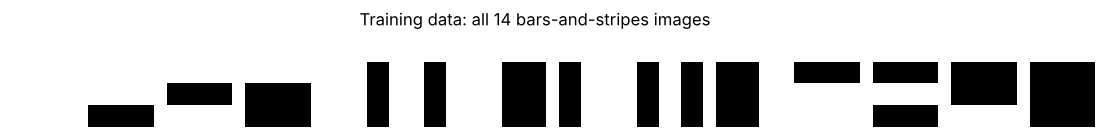

In [2]:
def bars_and_stripes(k=3):
    pats = set()
    for rows in itertools.product([0, 1], repeat=k):
        pats.add(tuple(np.repeat(rows, k)))           # bars: whole rows
    for cols in itertools.product([0, 1], repeat=k):
        pats.add(tuple(np.tile(cols, k)))             # stripes: whole columns
    return sorted(pats)

patterns = bars_and_stripes()
idx = [int("".join(map(str, p)), 2) for p in patterns]
p_data = np.zeros(2**N); p_data[idx] = 1 / len(idx)
valid = np.zeros(2**N, bool); valid[idx] = True
print(f"{len(patterns)} valid images out of {2**N} possible bitstrings")

fig, axes = plt.subplots(1, len(patterns), figsize=(14, 1.3))
for ax, p in zip(axes, patterns):
    ax.imshow(np.array(p).reshape(3, 3), cmap="Greys", vmin=0, vmax=1); ax.axis("off")
plt.suptitle("Training data: all 14 bars-and-stripes images", y=1.15); plt.show()

def kl(p, q, eps=1e-12):
    m = p > 0
    return float(np.sum(p[m] * np.log(p[m] / (q[m] + eps))))

results = {}

## Baseline 1: independent pixels
Every pixel is on in exactly half of the images, so the best independent model is uniform over all 512 bitstrings.

In [3]:
bits = np.array([[int(b) for b in format(i, "09b")] for i in range(2**N)])
marg = (p_data[:, None] * bits).sum(0)
q_ind = np.prod(np.where(bits == 1, marg, 1 - marg), axis=1)
results["Independent pixels"] = dict(params=N, kl=kl(p_data, q_ind), valid=q_ind[valid].sum())
r = results["Independent pixels"]; print(f"KL = {r['kl']:.4f} nats, mass on valid images = {r['valid']:.1%}")

KL = 3.5993 nats, mass on valid images = 2.7%


## Baseline 2: fully visible Boltzmann machine (pairwise)
$p(x) \propto \exp(\sum_i h_i s_i + \sum_{i<j} J_{ij} s_i s_j)$ with $s = 2x - 1$. With 512 states we can compute the exact likelihood and fit it with L-BFGS.

In [4]:
spins = 2 * bits - 1
pairs = list(itertools.combinations(range(N), 2))
feats = np.hstack([spins, np.stack([spins[:, i] * spins[:, j] for i, j in pairs], 1)])

def nll(w):
    e = feats @ w
    logZ = np.logaddexp.reduce(e)
    q = np.exp(e - logZ)
    grad = -(p_data @ feats) + q @ feats
    return -(p_data @ (e - logZ)), grad

t = time.time()
res = minimize(nll, np.zeros(feats.shape[1]), jac=True, method="L-BFGS-B")
e = feats @ res.x; q_bm = np.exp(e - np.logaddexp.reduce(e))
results["Boltzmann machine (pairwise)"] = dict(params=feats.shape[1], kl=kl(p_data, q_bm), valid=q_bm[valid].sum())
r = results["Boltzmann machine (pairwise)"]; print(f"KL = {r['kl']:.2e} nats, mass on valid images = {r['valid']:.1%}, fit in {time.time() - t:.1f}s")

KL = 1.10e-08 nats, mass on valid images = 100.0%, fit in 0.0s


## The QCBM
Hardware-efficient ansatz: per layer, an RY and RZ rotation on every qubit followed by a ring of CNOTs, then a final RY layer.
Trained by minimising the exact KL divergence with Adam, gradients by automatic differentiation on the simulator.

KL = 0.2715 nats, mass on valid images = 82.5%, 99 parameters, trained in 22s


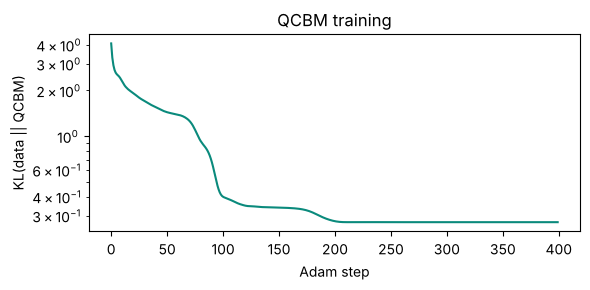

In [5]:
LAYERS = 5
dev = qml.device("default.qubit", wires=N)

@qml.qnode(dev, diff_method="backprop")
def qcbm(params):
    for l in range(LAYERS):
        for w in range(N):
            qml.RY(params[l, w, 0], wires=w)
            qml.RZ(params[l, w, 1], wires=w)
        for w in range(N):
            qml.CNOT(wires=[w, (w + 1) % N])
    for w in range(N):
        qml.RY(params[LAYERS, w, 0], wires=w)
    return qml.probs(wires=range(N))

target = pnp.array(p_data, requires_grad=False)
mask = target > 0
def loss(params):
    q = qcbm(params)
    return pnp.sum(target[mask] * (pnp.log(target[mask]) - pnp.log(q[mask] + 1e-10)))

params = pnp.array(np.random.uniform(0, 2 * np.pi, (LAYERS + 1, N, 2)), requires_grad=True)
n_params = LAYERS * N * 2 + N
opt = qml.AdamOptimizer(0.05)
history, t = [], time.time()
for step in range(400):
    params, l = opt.step_and_cost(loss, params)
    history.append(float(l))
q_qcbm = np.asarray(qcbm(params))
results["QCBM (9 qubits, 5 layers)"] = dict(params=n_params, kl=kl(p_data, q_qcbm), valid=q_qcbm[valid].sum())
r = results["QCBM (9 qubits, 5 layers)"]; print(f"KL = {r['kl']:.4f} nats, mass on valid images = {r['valid']:.1%}, {n_params} parameters, trained in {time.time() - t:.0f}s")

plt.figure(figsize=(6, 3)); plt.plot(history, color="#0a8a7c"); plt.yscale("log")
plt.xlabel("Adam step"); plt.ylabel("KL(data || QCBM)"); plt.title("QCBM training"); plt.tight_layout(); plt.show()

## Baseline 3: histogram of the training set
Included for honesty: on a dataset this small, simply storing the 14 images is perfect. Real generative modelling is about **generalising** to unseen data, which this notebook does not test.

In [6]:
results["Histogram (memorisation)"] = dict(params=len(patterns), kl=0.0, valid=1.0)

## Results

Model                               params  KL (nats)  mass on valid
Independent pixels                       9     3.5993          2.7%
Boltzmann machine (pairwise)            45     0.0000        100.0%
QCBM (9 qubits, 5 layers)               99     0.2715         82.5%
Histogram (memorisation)                14     0.0000        100.0%


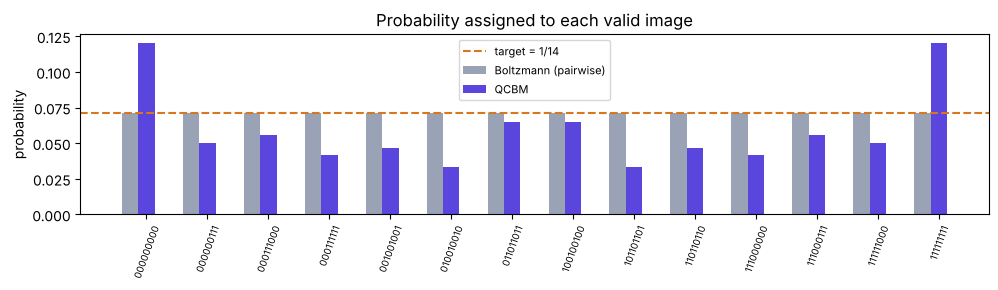

In [7]:
print(f"{'Model':34s} {'params':>7s} {'KL (nats)':>10s} {'mass on valid':>14s}")
for name, r in results.items():
    print(f"{name:34s} {r['params']:>7d} {r['kl']:>10.4f} {r['valid']:>13.1%}")

fig, ax = plt.subplots(figsize=(10, 3))
x = np.arange(len(idx)); wdt = 0.27
ax.bar(x - wdt, q_bm[idx], wdt, label="Boltzmann (pairwise)", color="#9aa3b5")
ax.bar(x, q_qcbm[idx], wdt, label="QCBM", color="#5a45dd")
ax.axhline(1 / len(idx), color="#d9771f", ls="--", label="target = 1/14")
ax.set_xticks(x); ax.set_xticklabels([format(i, "09b") for i in idx], rotation=70, fontsize=7)
ax.set_ylabel("probability"); ax.legend(fontsize=8); ax.set_title("Probability assigned to each valid image")
plt.tight_layout(); plt.show()

## Reading the results honestly

**This is a negative result for the quantum model, and we report it as such.**

- **Independent pixels** fail badly (KL ≈ 3.6 nats, under 3% of probability on valid images): bars-and-stripes is all about correlations.
- The **pairwise Boltzmann machine** (45 parameters) fits the distribution essentially perfectly: KL ≈ 0 and ~100% of probability on valid images. Pairwise interactions turn out to be enough for 3×3 bars-and-stripes.
- The **QCBM** (99 parameters) reaches KL ≈ 0.27 with about 82% of probability on valid images after 400 steps: clearly worse, with more than twice the parameters.
- The **histogram** is perfect because the dataset is tiny. A 512-state problem is trivially classical.

**Why publish this?** Because "quantum generative models beat classical ones" is often claimed on toy data without a strong classical baseline. Here the right baseline wins. Deeper circuits, better ansätze or longer training may close the gap, but the burden of proof is on the quantum model.

**Try next:** change `LAYERS`, the seed, or the learning rate; hold out some images to test generalisation; replace exact probabilities with a finite number of shots and an MMD loss, as on real hardware; or pick a dataset with higher-order structure that pairwise models *cannot* represent (see notebook 03).